In [7]:
import pandas as pd
import os
from pathlib import Path

In [8]:
weather_year = 2012
FES_year = 2022
FES_scenario = "LW"
future_year = 2050

In [9]:
# Paths
old_path = r'C:\Users\s2583817\Documents\Python\PyPSA-GB_Domestic_Heat\data\heat_demand_profiles'
new_path = new_path = Path(
    r"C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\heating_profiles\2010_2022_LW_2050"
)


print("Checking new_path:", os.path.abspath(new_path))
if not os.path.exists(new_path):
    raise FileNotFoundError(f"❌ Folder not found: {new_path}")
# Load Old Model
national_old = pd.DataFrame()
for file in os.listdir(old_path):
    if file.endswith('.csv') and FES_scenario in file and str(future_year) in file and str(weather_year) in file:
        df = pd.read_csv(os.path.join(old_path, file), index_col=0)
        df.index = pd.to_datetime(df.index)
        national_old = national_old.add(df, fill_value=0)
national_old_total = national_old.sum(axis=1)  # kWh per half-hour

# Load New Model
national_new = pd.DataFrame()
for file in os.listdir(new_path):
    if file.endswith('.csv') and 'half_hourly_heat_profile' in file:
        df = pd.read_csv(os.path.join(new_path, file), index_col=0)
        df.index = pd.to_datetime(df.index)
        national_new = national_new.add(df, fill_value=0)
national_new_total = national_new.sum(axis=1)  # kWh per half-hour


Checking new_path: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\heating_profiles\2010_2022_LW_2050


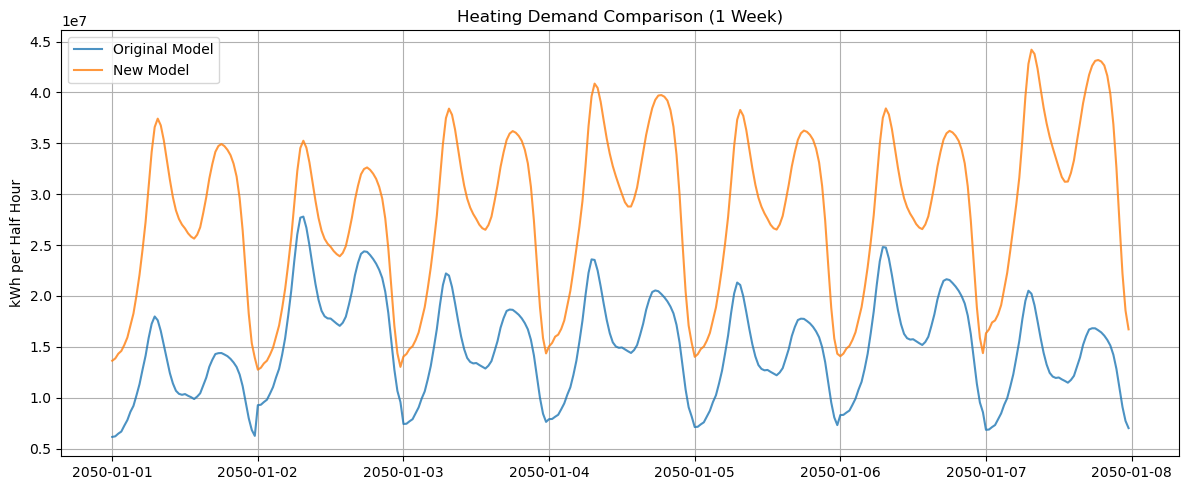

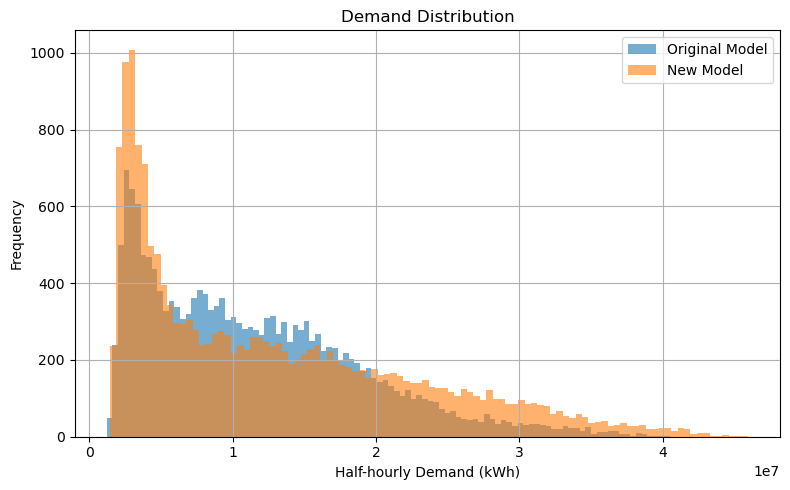

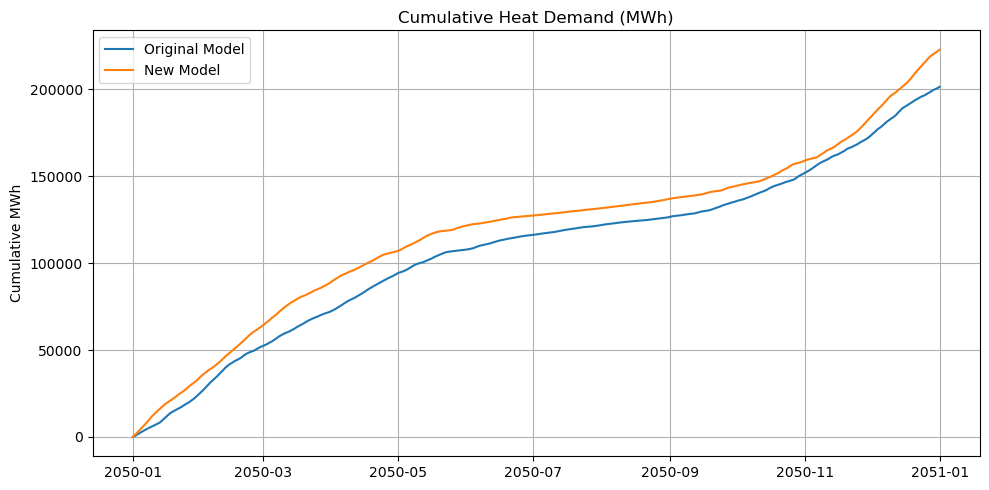

In [10]:
import matplotlib.pyplot as plt

# Plot 1: Time Series Comparison (e.g., 1 Week)
plt.figure(figsize=(12, 5))
start = '2050-01-01'
end = '2050-01-07'
plt.plot(national_old_total[start:end], label='Original Model', alpha=0.8)
plt.plot(national_new_total[start:end], label='New Model', alpha=0.8)
plt.title('Heating Demand Comparison (1 Week)')
plt.ylabel('kWh per Half Hour')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Plot 2: Histogram of Demand Distributions
plt.figure(figsize=(8, 5))
plt.hist(national_old_total, bins=100, alpha=0.6, label='Original Model')
plt.hist(national_new_total, bins=100, alpha=0.6, label='New Model')
plt.title('Demand Distribution')
plt.xlabel('Half-hourly Demand (kWh)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot 3: Cumulative Energy
plt.figure(figsize=(10, 5))
plt.plot(national_old_total.cumsum() / 1e6, label='Original Model')
plt.plot(national_new_total.cumsum() / 1e6, label='New Model')
plt.title('Cumulative Heat Demand (MWh)')
plt.ylabel('Cumulative MWh')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


<module 'matplotlib.pyplot' from 'c:\\Users\\s2583817\\AppData\\Local\\miniconda3\\envs\\GBheat\\lib\\site-packages\\matplotlib\\pyplot.py'>

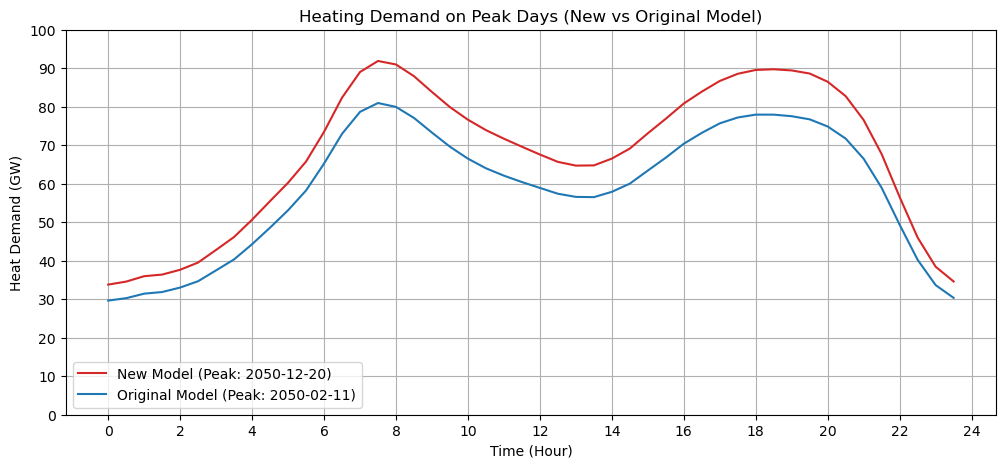

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# --- Peak Day: New Model ---
peak_timestamp_new = national_new_total.idxmax()
peak_day_new = peak_timestamp_new.normalize()
day_data_new = national_new_total.loc[peak_day_new : peak_day_new + pd.Timedelta(hours=23, minutes=30)]

if len(day_data_new) != 48:
    print(f"⚠️ New Model: Expected 48 entries, got {len(day_data_new)}")

day_data_new_gw = day_data_new * 2 / 1e6  # Convert to GW

# --- Peak Day: Old Model ---
peak_timestamp_Original = national_old_total.idxmax()
peak_day_Original = peak_timestamp_Original.normalize()
day_data_Original = national_old_total.loc[peak_day_Original : peak_day_Original + pd.Timedelta(hours=23, minutes=30)]

if len(day_data_Original) != 48:
    print(f"⚠️ Old Model: Expected 48 entries, got {len(day_data_Original)}")

day_data_Original_gw = day_data_Original * 2 / 1e6  # Convert to GW

# --- Plotting ---
x_hours = [i * 0.5 for i in range(48)]

plt.figure(figsize=(12, 5))
plt.plot(x_hours, day_data_new_gw, label=f'New Model (Peak: {peak_day_new.date()})', color='tab:red')
plt.plot(x_hours, day_data_Original_gw, label=f'Original Model (Peak: {peak_day_Original.date()})', color='tab:blue')

plt.title('Heating Demand on Peak Days (New vs Original Model)')
plt.xlabel('Time (Hour)')
plt.ylabel('Heat Demand (GW)')
plt.xticks(range(0, 25, 2))  # 0 to 24 hours
plt.yticks(range(0, int(max(day_data_new_gw.max(), day_data_Original_gw.max())) + 10, 10))  # Auto-scale y-axis
plt.legend()
plt.grid(True)
plt


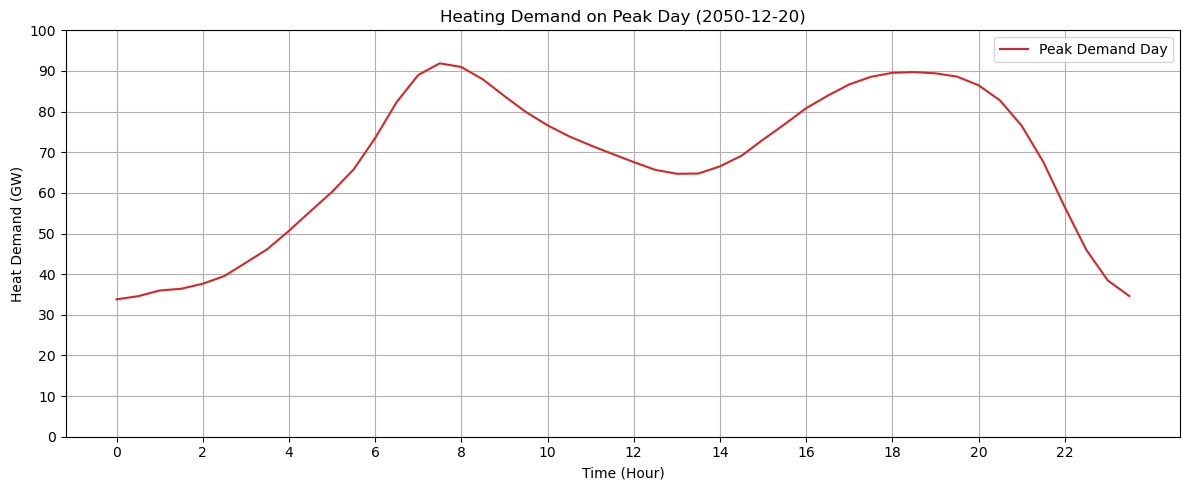

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# Step 1: Find timestamp of peak demand
peak_timestamp = national_new_total.idxmax()

# Step 2: Get the full date (truncate time)
peak_day = peak_timestamp.normalize()

# Step 3: Extract exactly 48 time steps from that date
day_data = national_new_total.loc[peak_day : peak_day + pd.Timedelta(hours=23, minutes=30)]

# Sanity check
if len(day_data) != 48:
    print(f"⚠️ Warning: Expected 48 entries, got {len(day_data)}")

# Step 4: Convert from kWh to GW (each value is for half-hour)
day_data_gw = day_data * 2 / 1e6

# Step 5: Generate x-axis (0 to 24 in 0.5 steps)
x_hours = [i * 0.5 for i in range(len(day_data_gw))]

# Plotting
plt.figure(figsize=(12, 5))
plt.plot(x_hours, day_data_gw, label='Peak Demand Day', color='tab:red')

plt.title(f'Heating Demand on Peak Day ({peak_day.date()})')
plt.xlabel('Time (Hour)')
plt.ylabel('Heat Demand (GW)')
plt.xticks(range(0, 24, 2))  # x-axis: 0 to 24 hours
plt.yticks(range(0, int(day_data_gw.max()) + 10, 10))  # y-axis in 10 GW steps


plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



In [13]:
# Calculate peak demand (convert kWh per 30 min to GW)
old_peak = national_old_total.max() * 2 / 1e6  # GW
new_peak = national_new_total.max() * 2 / 1e6  # GW

# Calculate max ramp rate (change in demand between intervals, in GW/h)
old_ramp = national_old_total.diff().abs().max() * 2 / 1e6  # GW/h
new_ramp = national_new_total.diff().abs().max() * 2 / 1e6  # GW/h


In [14]:
print(f"Old Peak: {old_peak:.2f} GW, Ramp: {old_ramp:.2f} GW/h")
print(f"New Peak: {new_peak:.2f} GW, Ramp: {new_ramp:.2f} GW/h")


Old Peak: 80.96 GW, Ramp: 10.40 GW/h
New Peak: 91.88 GW, Ramp: 11.14 GW/h


In [15]:
import matplotlib.dates as mdates
air_temp_path = r"C:\Users\s2583817\Documents\Python\PyPSA-GB_Domestic_Heat\data\LA_UK\air_temp"
file_name = "average_day_air_temp_2012.csv"
# ✅ Join path correctly
full_path = os.path.join(air_temp_path, file_name)

# ✅ Now read the file
air_temp = pd.read_csv(full_path, index_col=0, parse_dates=True)



C:\Users\s2583817\AppData\Local\Temp\ipykernel_11424\4182389518.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  air_temp = pd.read_csv(full_path, index_col=0, parse_dates=True)


In [16]:
# Average temperature across all LAs (columns)
air_temp_daily = air_temp.mean(axis=1)  # length = 366
# Create a date index starting from Jan 1
air_temp_daily.index = pd.date_range(start='2012-01-01', periods=366, freq='D')


In [17]:
# Upsample to half-hourly
air_temp_half_hourly = air_temp_daily.resample('30min').interpolate('linear')

# Truncate to 17520 rows (in case it gives one extra due to interpolation)
air_temp_half_hourly = air_temp_half_hourly.iloc[:17520]
air_temp_half_hourly

2012-01-01 00:00:00    9.209005
2012-01-01 00:30:00    9.117391
2012-01-01 01:00:00    9.025777
2012-01-01 01:30:00    8.934163
2012-01-01 02:00:00    8.842550
                         ...   
2012-12-30 21:30:00    8.964264
2012-12-30 22:00:00    9.019287
2012-12-30 22:30:00    9.074311
2012-12-30 23:00:00    9.129334
2012-12-30 23:30:00    9.184357
Freq: 30min, Length: 17520, dtype: float64

In [18]:
# Convert demand to Series with matching index
demand_series = pd.Series(national_old_total.values, index=range(17520))
temp_series = pd.Series(air_temp_half_hourly.values, index=range(17520))

# Normalize
demand_norm = (demand_series - demand_series.min()) / (demand_series.max() - demand_series.min())
temp_norm = (temp_series - temp_series.min()) / (temp_series.max() - temp_series.min())


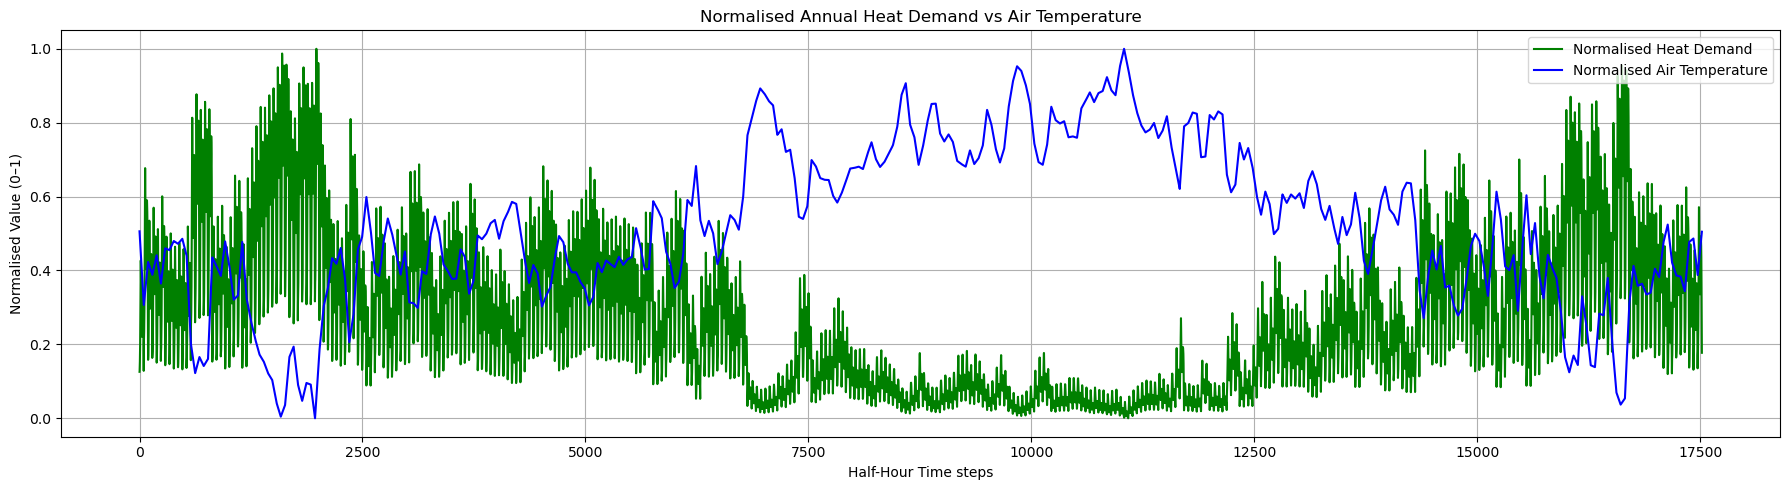

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 5))
plt.plot(demand_norm, label='Normalised Heat Demand', color='green')
plt.plot(temp_norm, label='Normalised Air Temperature', color='blue')
plt.title("Normalised Annual Heat Demand vs Air Temperature")
plt.xlabel("Half-Hour Time steps")
plt.ylabel("Normalised Value (0–1)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [20]:


air_temp_path = r"C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\data\LA_UK\new_version\air_temp_new"
file_name = "average_day_air_temp_2012.csv"
full_path = os.path.join(air_temp_path, file_name)

# Read daily air temperature data
air_temp = pd.read_csv(full_path, index_col=0, parse_dates=True)

# Step 2: National daily average temperature (across LAs)
air_temp_daily = air_temp.mean(axis=1)
air_temp_daily.index = pd.date_range(start='2012-01-01', periods=366, freq='D')

plt.show()


C:\Users\s2583817\AppData\Local\Temp\ipykernel_11424\2890934713.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  air_temp = pd.read_csv(full_path, index_col=0, parse_dates=True)


In [21]:
# Interpolate to half-hourly (48 per day → total 17,520)
air_temp_half_hourly = air_temp_daily.resample('30min').interpolate('linear')
air_temp_half_hourly = air_temp_half_hourly.iloc[:17520]



In [22]:
# Align by position and normalize
demand_series = pd.Series(national_new_total.values, index=range(17520))
temp_series = pd.Series(air_temp_half_hourly.values, index=range(17520))

demand_norm = (demand_series - demand_series.min()) / (demand_series.max() - demand_series.min())
temp_norm = (temp_series - temp_series.min()) / (temp_series.max() - temp_series.min())


C:\Users\s2583817\AppData\Local\Temp\ipykernel_11424\3206046096.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  air_temp = pd.read_csv(


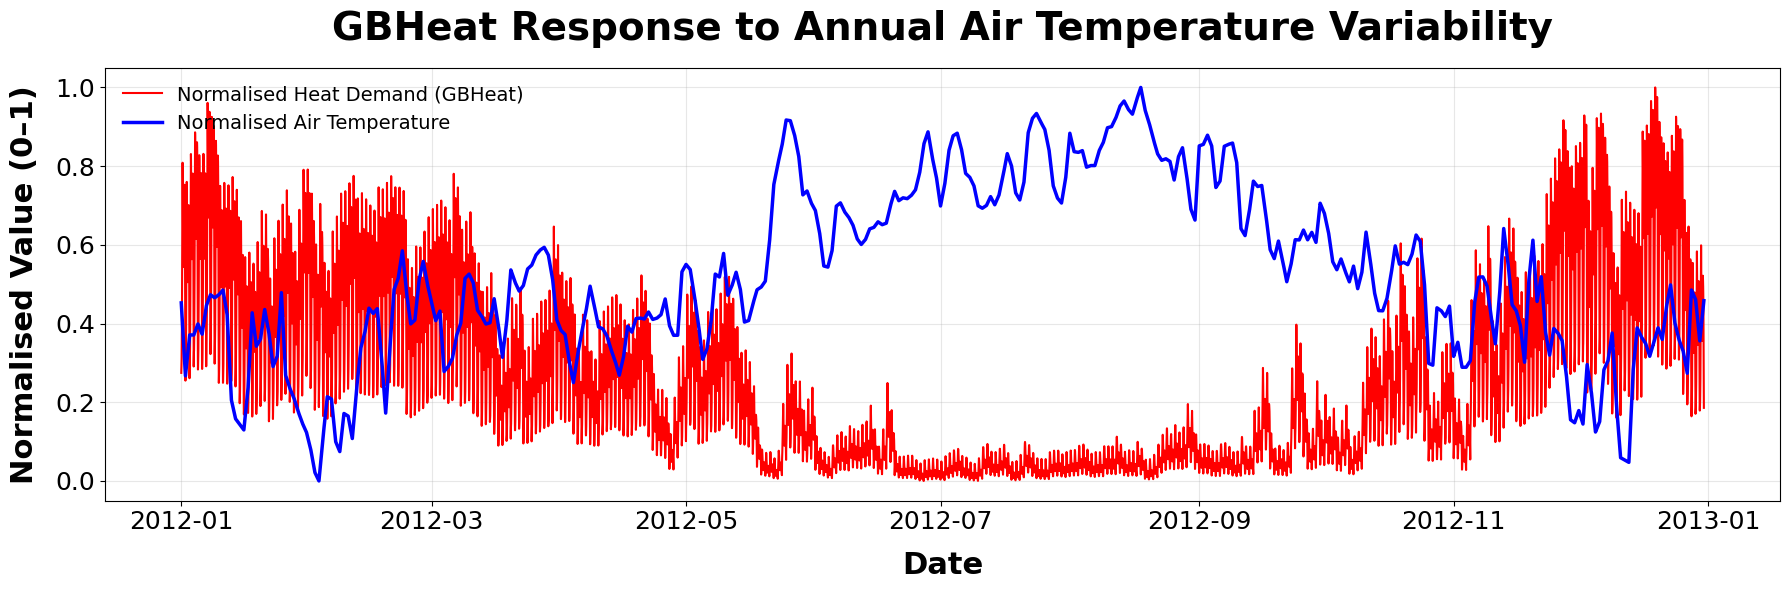

In [27]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Load daily air-temperature data
# ============================================================

air_temp_path = (
    r"C:\Users\s2583817\OneDrive - University of Edinburgh"
    r"\Documents\Projects\PhD_Project\Python\GB_Residential_Heating"
    r"\data\LA_UK\new_version\air_temp_new"
)

file_name = "average_day_air_temp_2012.csv"
full_path = os.path.join(air_temp_path, file_name)

air_temp = pd.read_csv(
    full_path,
    index_col=0,
    parse_dates=True
)

# ============================================================
# 2. Calculate national daily mean air temperature
# ============================================================

air_temp_daily = air_temp.mean(axis=1)

# Ensure correct daily datetime index for leap year 2012
air_temp_daily.index = pd.date_range(
    start="2012-01-01",
    periods=len(air_temp_daily),
    freq="D"
)

# ============================================================
# 3. Interpolate daily temperature to half-hourly resolution
# ============================================================

air_temp_half_hourly = (
    air_temp_daily
    .resample("30min")
    .interpolate(method="linear")
)

# ============================================================
# 4. Align heat demand and temperature series
# ============================================================

# Use the common available length rather than hard-coding 17,520
n_steps = min(
    len(national_new_total),
    len(air_temp_half_hourly)
)

demand_series = pd.Series(
    national_new_total.values[:n_steps],
    index=air_temp_half_hourly.index[:n_steps]
)

temp_series = pd.Series(
    air_temp_half_hourly.values[:n_steps],
    index=air_temp_half_hourly.index[:n_steps]
)

# ============================================================
# 5. Min-max normalisation
# ============================================================

demand_norm = (
    (demand_series - demand_series.min())
    / (demand_series.max() - demand_series.min())
)

temp_norm = (
    (temp_series - temp_series.min())
    / (temp_series.max() - temp_series.min())
)

# ============================================================
# 6. Plot — consistent paper style
# ============================================================

fig, ax = plt.subplots(figsize=(18, 6))

ax.plot(
    demand_norm.index,
    demand_norm.values,
    label="Normalised Heat Demand (GBHeat)",
    color="red",
    linewidth=1.5
)

ax.plot(
    temp_norm.index,
    temp_norm.values,
    label="Normalised Air Temperature",
    color="blue",
    linewidth=2.5 
)

# ------------------------------------------------------------
# Title and axis labels
# ------------------------------------------------------------

ax.set_title(
    "GBHeat Response to Annual Air Temperature Variability",
    fontsize=28,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Date",
    fontsize=22,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Normalised Value (0–1)",
    fontsize=22,
    fontweight="bold",
    labelpad=12
)

# ------------------------------------------------------------
# Tick labels
# ------------------------------------------------------------

ax.tick_params(
    axis="both",
    which="major",
    labelsize=18
)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

ax.legend(
    fontsize=14,
    frameon=False
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

In [24]:
print("Watson:", type(watson_df), watson_df.shape)
print("Sansom:", type(sansom_df), sansom_df.shape)

display(watson_df.head())
display(sansom_df.head())

NameError: name 'watson_df' is not defined

In [ ]:
print("Watson:", type(watson_df), watson_df.shape)
print("Sansom:", type(sansom_df), sansom_df.shape)

display(watson_df.head())
display(sansom_df.head())

In [ ]:
national_hp__old_df = national_old_total[['ASHP', 'GSHP']].copy()
national_hp__old_df